In [132]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [133]:
food_delivery=pd.read_excel(r"C:\Users\sriva\Desktop\ml_models\food_delivery_time_prediction\food_delivery_dataset.xlsx")
food_delivery

,Order_ID,City,Distance_km,Traffic_Level,Weather_Conditions,Vehicle_Type,Order_Type,Time_of_Day,Order_Date,Day_of_Week,...,Restaurant_Preparation_Time_min,Number_of_Items,Restaurant_Active_Orders,Delivery_Partner_Experience_months,Restaurant_Rating,Delivery_Partner_Rating,Rainfall_mm,Temperature_C,Order_Value_INR,Delivery_Time_Minutes
0,ORD100177,Bengaluru,4.1,Light,Sunny,Bike,Regular,Breakfast,02-28-25,Friday,...,19,7,9,67,3.2,4,0,38.4,1737,36
1,ORD100396,Kolkata,4.4,Medium,Clouds,Bike,Regular,Dinner,01-17-25,Friday,...,32,7,23,0.2 years,4.5,4.9,0,31,943,61
2,ORD101689,HYDERABAD,3.2,High,sunny,Electric Scooter,REGULAR,Lunch,2025-02-04,Tuesday,...,20,5,11,80,NaN,4.1,0,31.3,1054,41
3,ORD101634,Punee,-,L,cloudy,Scooter,Scheduled,Lunch,01/06/2025,Sunday,...,26,9,3,NaN,4.2,NaN,0,24.7,1814,48
4,ORD101633,Mumbai,3.3,Medium,Rainy,Bike,Regular,Dinner,2025-11-18,Tuesday,...,17,6,2,21m,4.7,4.2,36.6,30.3,1123,40
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2323,ORD101505,Hyderabad,8,Low,CLOUDY,Scooty,unknown,Breakfast,"March 30, 2025",sunday,...,16,1,0,NaN,NaN,3.6,unknown,20.1,316,36min
2324,ORD100435,Kolkata,3,Medium,Sunny,NaN,Regular,Late Night,2025-02-15,Saturday,...,NaN,7,NaN,56,4,3.8,0,27.7,1792,39
2325,ORD101011,Delhi,5.1,Medium,Sunny,Bike,Regular,Dinner,2025-10-19,Sunday,...,21 mins,7,18,2,NaN,4.1,25,30.4,869,48
2326,ORD100166,Hyderabad,3.9,High,Cloudy,Bike,Express,Breakfast,2025-04-28,Monday,...,12,4,1,92,4.6,3.3,0,22.4,1121,27


In [134]:
food_delivery.columns

Index(['Order_ID', 'City', 'Distance_km', 'Traffic_Level',
       'Weather_Conditions', 'Vehicle_Type', 'Order_Type', 'Time_of_Day',
       'Order_Date', 'Day_of_Week', 'Hour_of_Order', 'Is_Weekend',
       'Restaurant_Preparation_Time_min', 'Number_of_Items',
       'Restaurant_Active_Orders', 'Delivery_Partner_Experience_months',
       'Restaurant_Rating', 'Delivery_Partner_Rating', 'Rainfall_mm',
       'Temperature_C', 'Order_Value_INR', 'Delivery_Time_Minutes'],
      dtype='str')

In [135]:
food_delivery.info()

<class 'pandas.DataFrame'>
RangeIndex: 2328 entries, 0 to 2327
Data columns (total 22 columns):
 #   Column                              Non-Null Count  Dtype 
---  ------                              --------------  ----- 
 0   Order_ID                            2320 non-null   str   
 1   City                                2247 non-null   str   
 2   Distance_km                         2154 non-null   object
 3   Traffic_Level                       2192 non-null   str   
 4   Weather_Conditions                  2195 non-null   str   
 5   Vehicle_Type                        2214 non-null   str   
 6   Order_Type                          2233 non-null   str   
 7   Time_of_Day                         2213 non-null   str   
 8   Order_Date                          2255 non-null   str   
 9   Day_of_Week                         2225 non-null   str   
 10  Hour_of_Order                       2210 non-null   object
 11  Is_Weekend                          2225 non-null   object
 12  Res

In [136]:
food_delivery = food_delivery.drop(columns=[
    'Hour_of_Order',
    'Delivery_Partner_Experience_months',
    'Delivery_Partner_Rating',
    'Restaurant_Rating',
    'Temperature_C'
])

In [137]:
food_delivery.info()

<class 'pandas.DataFrame'>
RangeIndex: 2328 entries, 0 to 2327
Data columns (total 17 columns):
 #   Column                           Non-Null Count  Dtype 
---  ------                           --------------  ----- 
 0   Order_ID                         2320 non-null   str   
 1   City                             2247 non-null   str   
 2   Distance_km                      2154 non-null   object
 3   Traffic_Level                    2192 non-null   str   
 4   Weather_Conditions               2195 non-null   str   
 5   Vehicle_Type                     2214 non-null   str   
 6   Order_Type                       2233 non-null   str   
 7   Time_of_Day                      2213 non-null   str   
 8   Order_Date                       2255 non-null   str   
 9   Day_of_Week                      2225 non-null   str   
 10  Is_Weekend                       2225 non-null   object
 11  Restaurant_Preparation_Time_min  2153 non-null   object
 12  Number_of_Items                  2219 non-nul

In [138]:
food_delivery.head(5)

,Order_ID,City,Distance_km,Traffic_Level,Weather_Conditions,Vehicle_Type,Order_Type,Time_of_Day,Order_Date,Day_of_Week,Is_Weekend,Restaurant_Preparation_Time_min,Number_of_Items,Restaurant_Active_Orders,Rainfall_mm,Order_Value_INR,Delivery_Time_Minutes
0,ORD100177,Bengaluru,4.1,Light,Sunny,Bike,Regular,Breakfast,02-28-25,Friday,N,19,7,9,0,1737,36
1,ORD100396,Kolkata,4.4,Medium,Clouds,Bike,Regular,Dinner,01-17-25,Friday,NaN,32,7,23,0,943,61
2,ORD101689,HYDERABAD,3.2,High,sunny,Electric Scooter,REGULAR,Lunch,2025-02-04,Tuesday,0,20,5,11,0,1054,41
3,ORD101634,Punee,-,L,cloudy,Scooter,Scheduled,Lunch,01/06/2025,Sunday,1,26,9,3,0,1814,48
4,ORD101633,Mumbai,3.3,Medium,Rainy,Bike,Regular,Dinner,2025-11-18,Tuesday,0,17,6,2,36.6,1123,40


In [139]:
food_delivery.isnull().sum()

Order_ID                             8
City                                81
Distance_km                        174
Traffic_Level                      136
Weather_Conditions                 133
Vehicle_Type                       114
Order_Type                          95
Time_of_Day                        115
Order_Date                          73
Day_of_Week                        103
Is_Weekend                         103
Restaurant_Preparation_Time_min    175
Number_of_Items                    109
Restaurant_Active_Orders           148
Rainfall_mm                        161
Order_Value_INR                    132
Delivery_Time_Minutes               60
dtype: int64

In [140]:
food_delivery['City'].unique()

<StringArray>
[  'Bengaluru',     'Kolkata',   'HYDERABAD',       'Punee',      'Mumbai',
   'Hyderabad',   'bengaluru',        'Pune',       'Delhi',     'Chennai',
       'delhi',     'unknown',  ' Hyderabad',      'mumbai',           nan,
   'Bengalore',       'Poona',       'DELHI',    'Hyderbad',       'Dilli',
 'Bengaluru  ',     'KOLKATA',           '-',    'Mumbai  ',   'Kolkata  ',
         'Hyd',    'Calcutta',           '?',    'CALCUTTA', 'Hyderabad  ',
        'pune',     'Delhi  ',  ' Bengaluru',    'Kolkatta',      'Bombay',
      'Chenai',      ' Delhi',      'Madras',     ' Mumbai',   'BENGALURU',
   'hyderabad',    ' Chennai',   'Bangalore',         'NCR',       ' Pune',
         'BLR',     'kolkata',   'KOLKATA  ',     'chennai',     ' MUMBAI',
        'PUNE',    ' Kolkata',      'PUNE  ',    'Hydrabad',      'MUMBAI',
      'Pune  ',     'CHENNAI',   'Chennai  ',      'Mumbay',   'New Delhi',
     'DELHI  ',    'MUMBAI  ', 'HYDERABAD  ',      'MADRAS']
Length: 64, d

In [141]:
food_delivery['City']=food_delivery['City'].str.title()

In [142]:
food_delivery['City']=food_delivery['City'].str.strip()

In [143]:
food_delivery['City']=food_delivery['City'].replace('Bengalore','Bengaluru')
food_delivery['City']=food_delivery['City'].replace('Bangalore','Bengaluru')
food_delivery['City']=food_delivery['City'].replace('Blr','Bengaluru')
food_delivery['City']=food_delivery['City'].replace('Hyderbad','Hyderabad')
food_delivery['City']=food_delivery['City'].replace('Hyd','Hyderabad')
food_delivery['City']=food_delivery['City'].replace('Hydrabad','Hyderabad')
food_delivery['City']=food_delivery['City'].replace('Punee','Pune')
food_delivery['City']=food_delivery['City'].replace('Poona','Pune')
food_delivery['City']=food_delivery['City'].replace('Mumbay','Mumbai')
food_delivery['City']=food_delivery['City'].replace('Bombay','Mumbai')
food_delivery['City']=food_delivery['City'].replace('New Delhi','Delhi')
food_delivery['City']=food_delivery['City'].replace('Ncr','Delhi',)
food_delivery['City']=food_delivery['City'].replace('Dilli','Delhi')
food_delivery['City']=food_delivery['City'].replace('Chenai','Chennai')
food_delivery['City']=food_delivery['City'].replace('Madras','Chennai')
food_delivery['City']=food_delivery['City'].replace('Kolkatta','Kolkata')
food_delivery['City']=food_delivery['City'].replace('Calcutta','Kolkata')

In [144]:
food_delivery['City'] = food_delivery['City'].replace(['Unknown', '-', '?'], np.nan)


In [145]:
food_delivery['City']=food_delivery['City'].fillna(food_delivery['City'].mode()[0])

In [146]:
food_delivery['Distance_km'].unique()

array([4.1, 4.4, 3.2, '-', 3.3, 2.8, 6.9, 6.2, 0.7, 7.2, 1.5, 13.3, 8.9,
       8.7, 3.5, '6.6KM', 14.3, 1, 9.8, 4, 5.4, 999, 7.1, 3.8, 5.1, 4.5,
       9.3, 3.7, 9.5, 6.8, nan, 5.3, 5.6, '3900 m', 10.8, -1, 10.6, 6.5,
       2, 2.9, 8.4, 60, '10.9 kms', 2.6, 4.2, '4700 m', 1.1, 3.1, 3.9,
       14.4, 10, '5.9KM', 4.3, 1.3, 7.4, 2.2, 3, 5.9, 9.9, 2.7, '6.3 kms',
       '3300 m', 4.7, '5.7 kms', 7.3, 'unknown', 5, 11.7, 9, 11.2, 1.6, 8,
       '5400 m', 5.8, 10.2, 8.2, 9.7, 4.8, 6.1, 1.7, 2.1, 4.6, 4.9,
       '3100 m', 2.4, '5.1 km', 6.6, '7.0 km', 3.4, '?', 6.7, 6.3, 16.4,
       '4.5 kms', 7.6, 5.2, 1.9, 7.7, '1600 m', 2.3, 6, 10.4, 7.9,
       '3.5 km', 19.5, 5.7, 7.5, '5000 m', '4.6KM', 20.9, 10.7, '2.9 km',
       12.6, 9.6, '8.2 kms', 10.9, 25, 7, '5.7 km', 11, 13.6, '6.5KM',
       6.4, '14100 m', 2.5, 8.6, '10.1KM', '2800 m', 13.2, 1.2, '8000 m',
       12.7, '3.3 kms', '3.9 km', 1.4, '9.9KM', '4200 m', 14.1, 0.9,
       '3400 m', '1800 m', 1.8, 11.3, 5.5, 0.5, 11.1, 12.5, 16.1

In [147]:
food_delivery['Distance_km']=pd.to_numeric(food_delivery['Distance_km'],errors="coerce")

In [148]:
food_delivery.loc[food_delivery['Distance_km'] <= 0,'Distance_km'] = np.nan

In [149]:
food_delivery['Distance_km']=food_delivery['Distance_km'].fillna(food_delivery['Distance_km'].median())

In [150]:
food_delivery['Traffic_Level'].unique()

<StringArray>
[    'Light',    'Medium',      'High',         'L',         nan,         'H',
       'Low',   'unknown',       'Jam',    'Jammed',     ' High',      ' Jam',
    'High  ',   ' Medium',      'high',     'Low  ',       'Mid',     'Jam  ',
       'LOW',       'Hgh',       'Med',      ' Low',      'HIGH',    'MEDIUM',
       'low',  'Medium  ',  'Moderate',    '  High',    'medium',  'Gridlock',
 ' Moderate',     'Heavy',         '-',       ' NA',         '?',       'JAM',
    ' Heavy',    ' Low  ',       'jam', 'Very High',   ' High  ', ' Medium  ',
      ' Hgh',   ' MEDIUM',     '  Low',      ' JAM',         ' ',   ' medium',
        ' L',  '  Medium']
Length: 50, dtype: str

In [151]:
food_delivery['Traffic_Level']=food_delivery['Traffic_Level'].str.title()

In [152]:
food_delivery['Traffic_Level']=food_delivery['Traffic_Level'].str.strip()

In [153]:
food_delivery['Traffic_Level']=food_delivery['Traffic_Level'].replace({'Light':'Low','L':'Low','H':'High','Jam':'High','Jammed':'High','Mid':'Medium','Hgh':'High','Med':'Medium','Moderate':'Medium','Heavy':'High','Very High':'High'})

In [154]:
food_delivery['Traffic_Level']=food_delivery['Traffic_Level'].replace(['-', 'Na', '?', '','Unknown'],np.nan)


In [155]:
food_delivery['Traffic_Level']=food_delivery['Traffic_Level'].fillna(food_delivery['Traffic_Level'].mode()[0])

In [156]:
food_delivery['Weather_Conditions'].unique()

<StringArray>
[       'Sunny',       'Clouds',        'sunny',       'cloudy',
        'Rainy',       'CLOUDY',       'Rainny',       'Sunnny',
       'Cloudy',        'SUNNY',       ' Foggy',         'Rain',
     'Cloudy  ',        'Foggy',      'Sunny  ',            nan,
        'rainy',       ' Rainy',      ' Cloudy',       ' Sunny',
            '?',     'Overcast',      'Foggy  ',            '-',
       'Stormy',        'Clear',        'RAINY',          'Fog',
      'unknown',        'Storm',      'Raining', 'Thunderstorm',
        'FOGGY',      ' Stormy',         'Mist',       'stormy',
      'Rainy  ',     'Stormy  ',        'foggy']
Length: 39, dtype: str

In [157]:
food_delivery['Weather_Conditions']=food_delivery['Weather_Conditions'].str.title().str.strip()

In [158]:
food_delivery['Weather_Conditions'] = (
    food_delivery['Weather_Conditions'].replace({'Rainny': 'Rainy','Sunnny': 'Sunny','Rain': 'Rainy','Raining': 'Rainy','Fog': 'Foggy','Mist': 'Foggy',
        'Storm':'Stormy','Clouds':'Cloudy',})
)

In [159]:
food_delivery['Weather_Conditions'] = (food_delivery['Weather_Conditions'].replace(['?', '-', 'Unknown', ''], np.nan))

In [160]:
food_delivery['Weather_Conditions'] = (food_delivery['Weather_Conditions'].fillna(food_delivery['Weather_Conditions'].mode()[0]))

In [161]:
food_delivery['Vehicle_Type'].unique()

<StringArray>
[              'Bike',   'Electric Scooter',            'Scooter',
         'Motorcycle',                 'bk',           ' Scooter',
            'Bicycle',          'E-Scooter', 'Electric Scooter  ',
             'Scootr',         'EV Scooter',                  nan,
             'Scooty',            'SCOOTER',               'BIKE',
   'ELECTRIC SCOOTER',          'Motorbike',            'unknown',
               'bike',   'Electric scooter',              ' Bike',
            'scooter',            'bicycle',                  '?',
             'Bike  ',          'Scooter  ',   'electric scooter',
  ' Electric Scooter',          'Bicycle  ',           ' Bicycle',
              'Cycle',                  '-',            'BICYCLE',
       'Bike (pedal)']
Length: 34, dtype: str

In [162]:
food_delivery['Vehicle_Type']=food_delivery['Vehicle_Type'].str.title().str.strip()

In [163]:
food_delivery['Vehicle_Type'] = food_delivery['Vehicle_Type'].replace({
    'Bk': 'Bike',
    'Motorbike': 'Motorcycle',
    'Scootr': 'Scooter',
    'Scooty': 'Scooter',
    'Ev Scooter': 'Electric Scooter',
    'E-Scooter': 'Electric Scooter',
    'Cycle': 'Bicycle',
    'Bike (Pedal)': 'Bicycle'
})

In [164]:
food_delivery['Vehicle_Type'] = food_delivery['Vehicle_Type'].replace(['Unknown', '?', '-', ''], np.nan)

In [165]:
food_delivery['Vehicle_Type'] = food_delivery['Vehicle_Type'].fillna(food_delivery['Vehicle_Type'].mode()[0])

In [166]:
food_delivery['Order_Type'].unique()

<StringArray>
[    'Regular',     'REGULAR',   'Scheduled',     'Express',        'Fast',
           nan,    ' Express',     'express',   'SCHEDULED',    ' Regular',
   'Regular  ',      'Normal',     'EXPRESS',    'Schedule',     'regular',
         'Std',         'Exp',           '-',   'Pre-order',  ' Scheduled',
 'Scheduled  ',     'unknown',           '?',   'Express  ',   'scheduled']
Length: 25, dtype: str

In [167]:
food_delivery['Order_Type']=food_delivery['Order_Type'].str.title().str.strip()

In [168]:
food_delivery['Order_Type']=food_delivery['Order_Type'].replace({'Fast':'Express','Normal':'Regular','Schedule':'Scheduled','Exp':'Express','Pre-Order':'Scheduled','Std':'Scheduled'})

In [169]:
food_delivery['Order_Type']=food_delivery['Order_Type'].replace(['-', 'Unknown', '?'],np.nan)

In [170]:
food_delivery['Order_Type']=food_delivery['Order_Type'].fillna(food_delivery['Order_Type'].mode()[0])

In [171]:
food_delivery['Time_of_Day'].unique()

<StringArray>
[   'Breakfast',       'Dinner',        'Lunch',            nan,
       'dinner',       ' Lunch',       'Snacks',        'Dinnr',
       'snacks',        'LUNCH',       'Brkfst',        'Night',
    'LateNight',   'Late Night',       'DINNER',      'Morning',
     'Snacks  ',    'Lunchtime',  ' Late Night',      ' Dinner',
   'Late night',      'Lunch  ',   'late night',    'breakfast',
    'BREAKFAST',       'SNACKS',            '?',      ' Snacks',
    'Afternoon',  'Breakfast  ',     'Dinner  ',        'Snack',
      'unknown',            '-',   ' Breakfast',      'Evening',
        'lunch',   'LATE NIGHT', 'Late Night  ']
Length: 39, dtype: str

In [172]:
food_delivery['Time_of_Day']=food_delivery['Time_of_Day'].str.title().str.strip()

In [173]:
food_delivery['Time_of_Day'] = food_delivery['Time_of_Day'].replace({'Dinnr': 'Dinner','Brkfst': 'Breakfast','Snack': 'Snacks','Lunchtime': 'Lunch','Late Night': 'Latenight'})

In [174]:
food_delivery['Time_of_Day'] = food_delivery['Time_of_Day'].replace(['?', '-', 'Unknown', ''], np.nan)

In [175]:
food_delivery['Time_of_Day'] = food_delivery['Time_of_Day'].fillna(food_delivery['Order_Type'].mode()[0])

In [176]:
food_delivery['Day_of_Week'].unique()

<StringArray>
[     'Friday',     'Tuesday',      'Sunday',    'Thursday',   'Wednesday',
    'THURSDAY',      'Monday',           '-',         'Mon',    'Saturday',
    'Monday  ',           nan,     'tuesday',     ' Friday',    'Friday  ',
    'Sunday  ',         'TUE',      'sunday',         'SAT',    'SATURDAY',
     'unknown',         'FRI',  'Saturday  ',  ' Wednesday',         'SUN',
   'wednesday',         'Thu',      'monday',         'Wed',   'Tuesday  ',
         'MON',   ' Saturday',      'MONDAY',      'friday',      'SUNDAY',
           '?',         'Sun',      'FRIDAY',   ' Thursday',     ' Sunday',
     'TUESDAY',    ' Tuesday',         'Tue',    'saturday',         'THU',
    'thursday',         'Fri',         'Sat',     ' Monday', 'Wednesday  ',
   'WEDNESDAY',         'WED',  'Thursday  ']
Length: 53, dtype: str

In [177]:
food_delivery['Day_of_Week']=food_delivery['Day_of_Week'].str.title().str.strip()

In [178]:
food_delivery['Day_of_Week']=food_delivery['Day_of_Week'].replace('Mon','Monday')
food_delivery['Day_of_Week']=food_delivery['Day_of_Week'].replace('Tue','Tuesday')
food_delivery['Day_of_Week']=food_delivery['Day_of_Week'].replace('Wed','Wednesday')
food_delivery['Day_of_Week']=food_delivery['Day_of_Week'].replace('Thu','Thursday')
food_delivery['Day_of_Week']=food_delivery['Day_of_Week'].replace('Fri','Friday')
food_delivery['Day_of_Week']=food_delivery['Day_of_Week'].replace('Sat','Saturday')
food_delivery['Day_of_Week']=food_delivery['Day_of_Week'].replace('Sun','Sunday')

In [179]:
food_delivery['Day_of_Week'] = food_delivery['Day_of_Week'].replace(
    ['-', 'Unknown', '?', ''], np.nan
)

In [180]:
food_delivery['Day_of_Week'] = food_delivery['Day_of_Week'].ffill()

In [181]:
food_delivery['Restaurant_Preparation_Time_min'].unique()

array([19, 32, 20, 26, 17, 21, 240, 18, '13 mins', 11, 16, 27, 14,
       '14 mins', 10, 25, '5 mins', 30, 9, 7, 13, 23, nan, 'unknown', 24,
       28, 12, 22, 8, '16 mins', '-', 15, '?', '11 mins', 29, '17 mins',
       '25 mins', '7 mins', '24 mins', 120, '27 mins', 31, 180, 5,
       '21 mins', '18 mins', '20 mins', '22 mins', '15 mins', '12 mins',
       37, '9 mins', 500, '29 mins', '26 mins', '23 mins', '28 mins',
       '31 mins', 33, '8 mins', 6, 34, '19 mins', '33 mins', '10 mins',
       35, '30 mins', '32 mins'], dtype=object)

In [182]:
food_delivery['Restaurant_Preparation_Time_min'] = pd.to_numeric(
    food_delivery['Restaurant_Preparation_Time_min'].astype('string').str.replace(' mins', '', regex=False).str.strip(),
    errors='coerce'
)

In [183]:
food_delivery['Restaurant_Preparation_Time_min']=food_delivery['Restaurant_Preparation_Time_min'].ffill()

In [184]:
food_delivery['Restaurant_Preparation_Time_min']=food_delivery['Restaurant_Preparation_Time_min'].astype(float)

In [185]:
food_delivery['Is_Weekend'].unique()

array(['N', nan, '0', 1, 0, 'Y', 'FALSE', 'TRUE', 'False', 'Yes', '1',
       'No', 'True', 'unknown', '?', '-'], dtype=object)

In [186]:
food_delivery['Is_Weekend']=food_delivery['Is_Weekend'].str.title()

In [187]:
food_delivery['Is_Weekend']=food_delivery['Is_Weekend'].replace('False',0)
food_delivery['Is_Weekend']=food_delivery['Is_Weekend'].replace('True',1)
food_delivery['Is_Weekend']=food_delivery['Is_Weekend'].replace('Yes',1)
food_delivery['Is_Weekend']=food_delivery['Is_Weekend'].replace('No',0)
food_delivery['Is_Weekend']=food_delivery['Is_Weekend'].replace('Y',1)
food_delivery['Is_Weekend']=food_delivery['Is_Weekend'].replace('N',0)
food_delivery['Is_Weekend']=food_delivery['Is_Weekend'].replace(['Unknown', '?', '-'],np.nan)
food_delivery['Is_Weekend']=food_delivery['Is_Weekend'].ffill()

In [188]:
food_delivery['Is_Weekend']=food_delivery['Is_Weekend'].astype(int)

In [189]:
food_delivery['Number_of_Items'].unique()

array([7, 5, 9, 6, 8, 1, 3, 4, nan, 2, 'unknown', 'four', 'five', 'one',
       'six', '-', '?', 'two', 'three', 99, 150, 0, -2], dtype=object)

In [190]:
food_delivery['Number_of_Items']=food_delivery['Number_of_Items'].replace('one',1)
food_delivery['Number_of_Items']=food_delivery['Number_of_Items'].replace('two',2)
food_delivery['Number_of_Items']=food_delivery['Number_of_Items'].replace('three',3)
food_delivery['Number_of_Items']=food_delivery['Number_of_Items'].replace('four',4)
food_delivery['Number_of_Items']=food_delivery['Number_of_Items'].replace('five',5)
food_delivery['Number_of_Items']=food_delivery['Number_of_Items'].replace('six',5)

In [191]:
food_delivery['Number_of_Items']=food_delivery['Number_of_Items'].replace(['unknown', '-', '?'],np.nan)

In [192]:
food_delivery['Number_of_Items']=food_delivery['Number_of_Items'].ffill()

In [193]:
food_delivery['Number_of_Items']=food_delivery['Number_of_Items'].abs()

In [194]:
food_delivery['Number_of_Items']=food_delivery['Number_of_Items'].astype(int)

In [195]:
food_delivery['Restaurant_Active_Orders'].unique()

array([9, 23, 11, 3, 2, 1, 7, 17, 22, 13, 10, nan, 4, 12, 19, 18, 24, 8,
       6, 5, 16, 21, 15, 0, 14, '?', -1, 20, '-', 'unknown', 500, -3],
      dtype=object)

In [196]:
food_delivery['Restaurant_Active_Orders']=food_delivery['Restaurant_Active_Orders'].replace(['-', 'unknown','?'],np.nan)

In [197]:
food_delivery['Restaurant_Active_Orders']=food_delivery['Restaurant_Active_Orders'].abs()

In [198]:
food_delivery['Restaurant_Active_Orders']=food_delivery['Restaurant_Active_Orders'].ffill()

In [199]:
food_delivery['Restaurant_Active_Orders']=food_delivery['Restaurant_Active_Orders'].astype(int)

In [200]:
food_delivery.isnull().sum()

Order_ID                             8
City                                 0
Distance_km                          0
Traffic_Level                        0
Weather_Conditions                   0
Vehicle_Type                         0
Order_Type                           0
Time_of_Day                          0
Order_Date                          73
Day_of_Week                          0
Is_Weekend                           0
Restaurant_Preparation_Time_min      0
Number_of_Items                      0
Restaurant_Active_Orders             0
Rainfall_mm                        161
Order_Value_INR                    132
Delivery_Time_Minutes               60
dtype: int64

In [201]:
food_delivery['Rainfall_mm'].unique()

array([0, 36.6, 35.9, 29.9, '?', 900, 16.8, 13.4, 31, 10.7, nan, 28.5,
       27.9, 5, '-', 20.6, 30, 10.6, 31.9, 19.6, 20.7, 17.8, 9.5, 6.3, 25,
       22.4, 36.9, 34.1, 15.6, 15.1, 38.9, 21.3, 8.5, 3.8, 2.6, 28.7,
       10.1, 37.2, 8.8, 4, 16.3, 24, 30.6, 28.1, 2.9, 18.4, 29.7, 18.7,
       7.3, 14.1, 16.7, 35.2, 21.4, 19.9, 28.9, 19.7, 16.4, 16.5, 17.1, 8,
       35, 5.8, 16.1, 11.1, 12.8, 9999, 11.6, 33.2, 5.3, 9.1, 18.6, 37.8,
       3, 6, 27.8, 25.2, 'unknown', 27.7, 10.4, 35.3, 12.7, 27.4, 24.3,
       19.4, 8.9, 8.6, 20.5, 2.3, 36.8, 26.5, 19.3, 37.4, 7, 22, 22.2,
       31.6, 20.3, 19.5, 31.2, 2.5, 13.5, 2.4, 7.7, 23.6, 36.4, 32.5,
       11.5, 33.9, 21.8, 28, 38.5, 6.8, 17.5, 37, 17.2, 13.2, 34.7, 17.4,
       4.4, 17.7, 10.5, 32.2, 26.2, 18.5, 30.8, 39.1, 11.9, 18, 24.7,
       25.8, 38, 20.9, 15.3, 34.2, 7.8, 22.6, 38.8, 33.8, 28.8, 12.4,
       12.2, 4.6, 25.7, 15.4, 38.2, 33.5, 30.9, 24.8, 4.2, 21.2, 19.1,
       21.1, 14.6, 37.9, 15.5, 1.6, 34.4, 32.1, 1.4, 25.9, 22.1, 

In [202]:
food_delivery['Rainfall_mm']=food_delivery['Rainfall_mm'].replace(['unknown','?','-'],np.nan)

In [203]:
food_delivery['Rainfall_mm']=food_delivery['Rainfall_mm'].ffill()

In [204]:
food_delivery['Rainfall_mm']=food_delivery['Rainfall_mm'].abs()

In [205]:
food_delivery['Order_Value_INR'].unique()

array([1737, 943, 1054, ..., 997, 193, 2159], shape=(1402,), dtype=object)

In [206]:
food_delivery["Order_Value_INR"] = pd.to_numeric(
    food_delivery["Order_Value_INR"], errors="coerce"
)

In [207]:
food_delivery['Order_Value_INR']=food_delivery['Order_Value_INR'].ffill()

In [208]:
food_delivery['Delivery_Time_Minutes'].unique()

array([36, 61, 41, 48, 40, 35, 56, 50, 21, 45, 62, '37min', 72, 31, nan,
       74, 18, 39, '57 min', '50 minutes', 69, 25, 49, 59, 26, 68, 46, 29,
       16, 33, '41 minutes', 52, 54, 34, 95, 76, 28, '48 minutes', 63, 27,
       57, 64, 43, '52 min', 51, '43min', 38, 32, 22, -1, '33min', 55, 53,
       44, '24 minutes', 30, 42, '65min', 70, '47 min', '52min', '?', 480,
       60, 58, 250, 24, '27 minutes', 47, 0, 23, '84 min', 99, 20, 67,
       1440, 65, '41 min', '46 min', '63 min', '97 min', '47min', 11, 37,
       73, '111 min', 84, '60 min', 75, '44 min', '51min', '42 min', 78,
       '50min', '55min', 79, 71, 81, '47 minutes', '35 minutes', 80,
       'unknown', 17, 15, '69 minutes', '68 min', '29 min', '53min',
       '54min', '35 min', 300, '21 min', '38 minutes', 66, '49min',
       '36min', '51 minutes', '38min', '41min', '30min', '57 minutes',
       '56 minutes', '48min', '38 min', '50 min', 19, '39min', 720, 89,
       '25min', '72 min', 83, '59 minutes', '44 minutes', '3

In [209]:
food_delivery['Delivery_Time_Minutes']=pd.to_numeric(food_delivery['Delivery_Time_Minutes'],errors='coerce')

In [210]:
food_delivery['Delivery_Time_Minutes']=food_delivery['Delivery_Time_Minutes'].abs()

In [211]:
food_delivery['Delivery_Time_Minutes']=food_delivery['Delivery_Time_Minutes'].fillna(food_delivery['Delivery_Time_Minutes'].mode()[0])

In [212]:
food_delivery['Order_Date'].unique()

<StringArray>
[         '02-28-25',          '01-17-25',        '2025-02-04',
        '01/06/2025',        '2025-11-18', 'December 25, 2025',
        '2025-08-13',        '2025-12-21',        '2025-11-13',
        '2025-03-28',
 ...
        '16/08/2025',        '2025-06-27',        '05/10/2025',
        '2025/07/18',       '21 Sep 2025',        '25/09/2025',
        '2025-03-23', 'February 24, 2025',        '2025/11/20',
          '12-20-25']
Length: 1016, dtype: str

In [213]:
food_delivery['Order_Date'] = pd.to_datetime(
    food_delivery['Order_Date'], format='mixed', errors='coerce'
)

In [214]:
food_delivery['Order_Date'] = food_delivery['Order_Date'].ffill()

In [215]:
food_delivery['Order_ID'].unique()

<StringArray>
['ORD100177', 'ORD100396', 'ORD101689', 'ORD101634', 'ORD101633', 'ORD101675',
 'ORD100671', 'ORD100403', 'ORD100491', 'ORD101307',
 ...
 'ORD101566', 'ORD100890', 'ORD101127', 'ORD101936', 'ORD100173', 'ORD101505',
 'ORD100435', 'ORD101011', 'ORD100166', 'ORD100283']
Length: 2101, dtype: str

In [216]:
food_delivery['Order_ID'].isnull().sum()

np.int64(8)

In [217]:
food_delivery['Order_ID'] = food_delivery['Order_ID'].ffill()

In [218]:
food_delivery.isnull().sum()

Order_ID                           0
City                               0
Distance_km                        0
Traffic_Level                      0
Weather_Conditions                 0
Vehicle_Type                       0
Order_Type                         0
Time_of_Day                        0
Order_Date                         0
Day_of_Week                        0
Is_Weekend                         0
Restaurant_Preparation_Time_min    0
Number_of_Items                    0
Restaurant_Active_Orders           0
Rainfall_mm                        0
Order_Value_INR                    0
Delivery_Time_Minutes              0
dtype: int64

In [219]:
food_delivery.duplicated().sum()

np.int64(75)

In [220]:
food_delivery=food_delivery.drop_duplicates()

In [221]:
food_delivery

,Order_ID,City,Distance_km,Traffic_Level,Weather_Conditions,Vehicle_Type,Order_Type,Time_of_Day,Order_Date,Day_of_Week,Is_Weekend,Restaurant_Preparation_Time_min,Number_of_Items,Restaurant_Active_Orders,Rainfall_mm,Order_Value_INR,Delivery_Time_Minutes
0,ORD100177,Bengaluru,4.1,Low,Sunny,Bike,Regular,Breakfast,2025-02-28,Friday,0,19.0,7,9,0,1737.0,36.0
1,ORD100396,Kolkata,4.4,Medium,Cloudy,Bike,Regular,Dinner,2025-01-17,Friday,0,32.0,7,23,0,943.0,61.0
2,ORD101689,Hyderabad,3.2,High,Sunny,Electric Scooter,Regular,Lunch,2025-02-04,Tuesday,0,20.0,5,11,0,1054.0,41.0
3,ORD101634,Pune,4.9,Low,Cloudy,Scooter,Scheduled,Lunch,2025-01-06,Sunday,0,26.0,9,3,0,1814.0,48.0
4,ORD101633,Mumbai,3.3,Medium,Rainy,Bike,Regular,Dinner,2025-11-18,Tuesday,0,17.0,6,2,36.6,1123.0,40.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2323,ORD101505,Hyderabad,8.0,Low,Cloudy,Scooter,Regular,Breakfast,2025-03-30,Sunday,1,16.0,1,0,0,316.0,41.0
2324,ORD100435,Kolkata,3.0,Medium,Sunny,Bike,Regular,Latenight,2025-02-15,Saturday,1,16.0,7,0,0,1792.0,39.0
2325,ORD101011,Delhi,5.1,Medium,Sunny,Bike,Regular,Dinner,2025-10-19,Sunday,1,21.0,7,18,25,869.0,48.0
2326,ORD100166,Hyderabad,3.9,High,Cloudy,Bike,Express,Breakfast,2025-04-28,Monday,0,12.0,4,1,0,1121.0,27.0


******* Distance_km *************


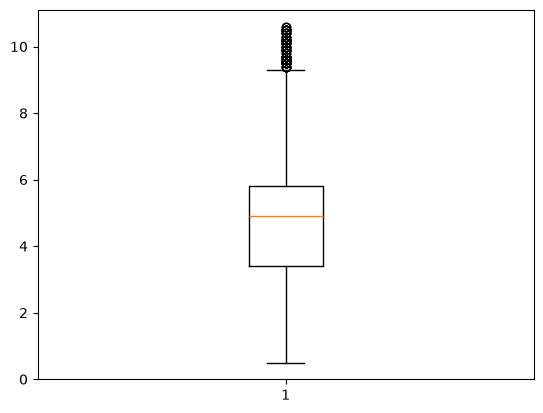

******* Is_Weekend *************


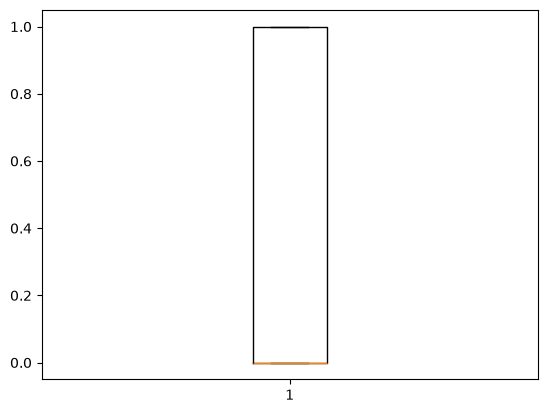

******* Restaurant_Preparation_Time_min *************


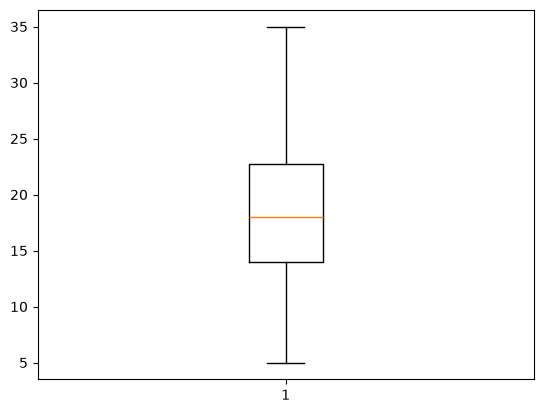

******* Number_of_Items *************


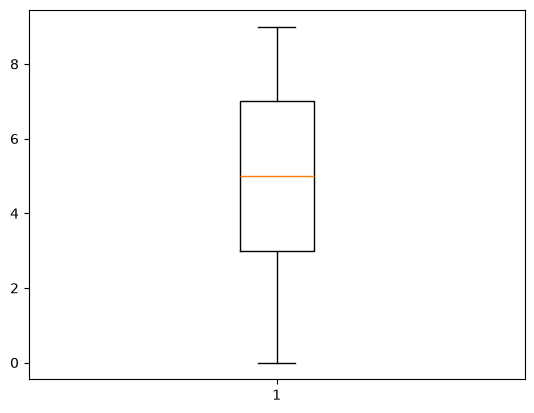

******* Restaurant_Active_Orders *************


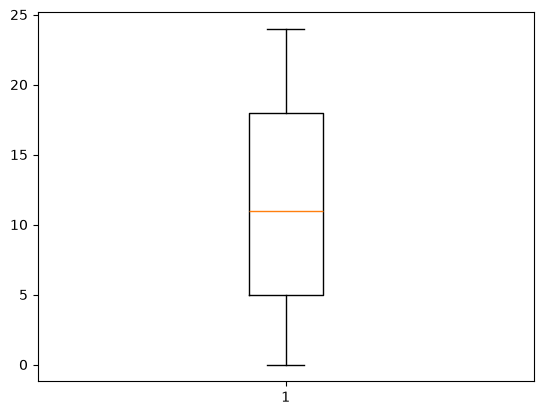

******* Order_Value_INR *************


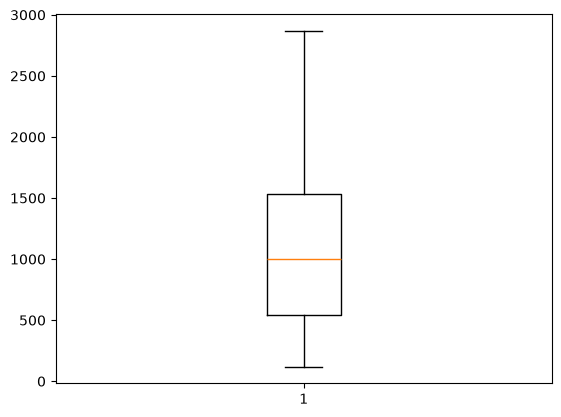

******* Delivery_Time_Minutes *************


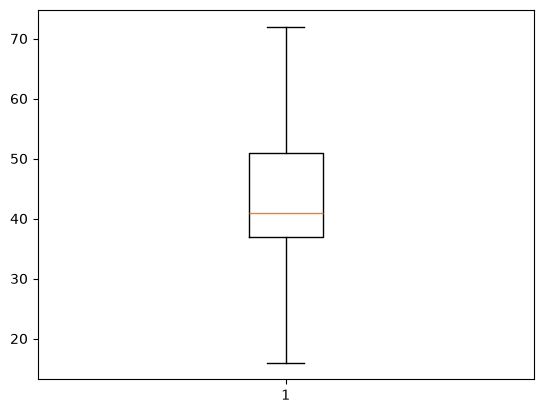

In [297]:
for i in food_delivery.columns:
    if food_delivery[i].dtypes==int or food_delivery[i].dtypes==float:
        print("*******",i,"*************")
        plt.boxplot(food_delivery[[i]])
        plt.show()  

In [223]:
Q1 = food_delivery['Distance_km'].quantile(0.25)
Q3 = food_delivery['Distance_km'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

food_delivery = food_delivery[
    (food_delivery['Distance_km'] >= lower_limit) &
    (food_delivery['Distance_km'] <= upper_limit)
]

In [224]:
Q1 = food_delivery['Restaurant_Active_Orders'].quantile(0.25)
Q3 = food_delivery['Restaurant_Active_Orders'].quantile(0.75)
IQR=Q3-Q1
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR
food_delivery=food_delivery[
    (food_delivery['Restaurant_Active_Orders'] >= lower_limit) &
    (food_delivery['Restaurant_Active_Orders'] <= upper_limit)
]

In [ ]:
Q1 = food_delivery['Number_of_Items'].quantile(0.25)
Q3 = food_delivery['Number_of_Items'].quantile(0.75)
IQR=Q3-Q1
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR
food_delivery=food_delivery[
    (food_delivery['Number_of_Items'] >= lower_limit) &
    (food_delivery['Number_of_Items'] <= upper_limit)
]

In [259]:
Q1 = food_delivery['Order_Value_INR'].quantile(0.25)
Q3 = food_delivery['Order_Value_INR'].quantile(0.75)
IQR=Q3-Q1
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR
food_delivery=food_delivery[
    (food_delivery['Order_Value_INR'] >= lower_limit) &
    (food_delivery['Order_Value_INR'] <= upper_limit)
]

In [296]:
Q1 = food_delivery['Restaurant_Preparation_Time_min'].quantile(0.25)
Q3 = food_delivery['Restaurant_Preparation_Time_min'].quantile(0.75)
IQR=Q3-Q1
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR
food_delivery=food_delivery[
    (food_delivery['Restaurant_Preparation_Time_min'] >= lower_limit) &
    (food_delivery['Restaurant_Preparation_Time_min'] <= upper_limit)
]

In [261]:
Q1 = food_delivery['Delivery_Time_Minutes'].quantile(0.25)
Q3 = food_delivery['Delivery_Time_Minutes'].quantile(0.75)
IQR=Q3-Q1
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR
food_delivery=food_delivery[
    (food_delivery['Delivery_Time_Minutes'] >= lower_limit) &
    (food_delivery['Delivery_Time_Minutes'] <= upper_limit)
]

In [257]:
# food_delivery = food_delivery[(food_delivery['Distance_km'] <= 8) &(food_delivery['Distance_km'] > 0)]

In [226]:
# food_delivery=food_delivery[(food_delivery['Restaurant_Active_Orders']<=150)&(food_delivery['Restaurant_Active_Orders']>=0)]

In [227]:
# food_delivery=food_delivery[(food_delivery['Order_Value_INR']<=2000)&(food_delivery['Order_Value_INR']>0)]

In [228]:
# food_delivery=food_delivery[(food_delivery['Number_of_Items']<=75)&(food_delivery['Number_of_Items']>0)]

In [229]:
# food_delivery=food_delivery[(food_delivery['Delivery_Time_Minutes']<=65)&(food_delivery['Delivery_Time_Minutes']>20)]

In [298]:
food_delivery

,Order_ID,City,Distance_km,Traffic_Level,Weather_Conditions,Vehicle_Type,Order_Type,Time_of_Day,Order_Date,Day_of_Week,Is_Weekend,Restaurant_Preparation_Time_min,Number_of_Items,Restaurant_Active_Orders,Rainfall_mm,Order_Value_INR,Delivery_Time_Minutes
0,ORD100177,Bengaluru,4.1,Low,Sunny,Bike,Regular,Breakfast,2025-02-28,Friday,0,19.0,7,9,0,1737.0,36.0
1,ORD100396,Kolkata,4.4,Medium,Cloudy,Bike,Regular,Dinner,2025-01-17,Friday,0,32.0,7,23,0,943.0,61.0
2,ORD101689,Hyderabad,3.2,High,Sunny,Electric Scooter,Regular,Lunch,2025-02-04,Tuesday,0,20.0,5,11,0,1054.0,41.0
3,ORD101634,Pune,4.9,Low,Cloudy,Scooter,Scheduled,Lunch,2025-01-06,Sunday,0,26.0,9,3,0,1814.0,48.0
4,ORD101633,Mumbai,3.3,Medium,Rainy,Bike,Regular,Dinner,2025-11-18,Tuesday,0,17.0,6,2,36.6,1123.0,40.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2323,ORD101505,Hyderabad,8.0,Low,Cloudy,Scooter,Regular,Breakfast,2025-03-30,Sunday,1,16.0,1,0,0,316.0,41.0
2324,ORD100435,Kolkata,3.0,Medium,Sunny,Bike,Regular,Latenight,2025-02-15,Saturday,1,16.0,7,0,0,1792.0,39.0
2325,ORD101011,Delhi,5.1,Medium,Sunny,Bike,Regular,Dinner,2025-10-19,Sunday,1,21.0,7,18,25,869.0,48.0
2326,ORD100166,Hyderabad,3.9,High,Cloudy,Bike,Express,Breakfast,2025-04-28,Monday,0,12.0,4,1,0,1121.0,27.0


In [299]:
l=[]
for i in food_delivery.columns:
    if food_delivery[i].dtypes in (int,float):
        l.append(i)

In [300]:
import seaborn as sns
a=np.array(l)

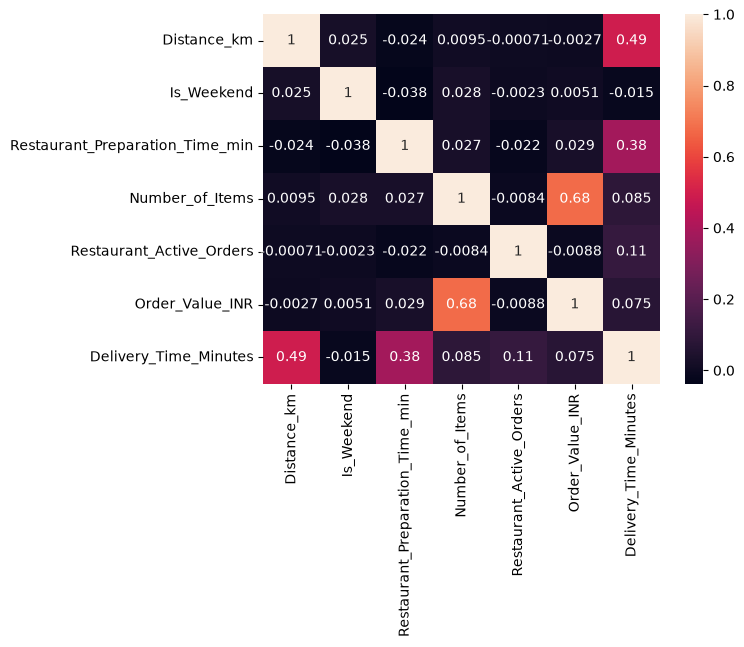

In [301]:
sns.heatmap(food_delivery[a].corr(),annot=True)
plt.show()

In [302]:
food_delivery.to_csv("FOOD_DELIVERY_REPORT",index=False)

ML_PROJECT


In [303]:
from sklearn.model_selection import train_test_split
# from sklearn.linear_model import LinearRegression                                               
from sklearn.ensemble import RandomForestRegressor
# from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

In [304]:
order_time=pd.read_csv(r"C:\Users\sriva\Desktop\ml_models\food_delivery_time_prediction\FOOD_DELIVERY_REPORT")

In [305]:
order_time

,Order_ID,City,Distance_km,Traffic_Level,Weather_Conditions,Vehicle_Type,Order_Type,Time_of_Day,Order_Date,Day_of_Week,Is_Weekend,Restaurant_Preparation_Time_min,Number_of_Items,Restaurant_Active_Orders,Rainfall_mm,Order_Value_INR,Delivery_Time_Minutes
0,ORD100177,Bengaluru,4.1,Low,Sunny,Bike,Regular,Breakfast,2025-02-28,Friday,0,19.0,7,9,0.0,1737.0,36.0
1,ORD100396,Kolkata,4.4,Medium,Cloudy,Bike,Regular,Dinner,2025-01-17,Friday,0,32.0,7,23,0.0,943.0,61.0
2,ORD101689,Hyderabad,3.2,High,Sunny,Electric Scooter,Regular,Lunch,2025-02-04,Tuesday,0,20.0,5,11,0.0,1054.0,41.0
3,ORD101634,Pune,4.9,Low,Cloudy,Scooter,Scheduled,Lunch,2025-01-06,Sunday,0,26.0,9,3,0.0,1814.0,48.0
4,ORD101633,Mumbai,3.3,Medium,Rainy,Bike,Regular,Dinner,2025-11-18,Tuesday,0,17.0,6,2,36.6,1123.0,40.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1937,ORD101505,Hyderabad,8.0,Low,Cloudy,Scooter,Regular,Breakfast,2025-03-30,Sunday,1,16.0,1,0,0.0,316.0,41.0
1938,ORD100435,Kolkata,3.0,Medium,Sunny,Bike,Regular,Latenight,2025-02-15,Saturday,1,16.0,7,0,0.0,1792.0,39.0
1939,ORD101011,Delhi,5.1,Medium,Sunny,Bike,Regular,Dinner,2025-10-19,Sunday,1,21.0,7,18,25.0,869.0,48.0
1940,ORD100166,Hyderabad,3.9,High,Cloudy,Bike,Express,Breakfast,2025-04-28,Monday,0,12.0,4,1,0.0,1121.0,27.0


In [306]:
order_time.columns

Index(['Order_ID', 'City', 'Distance_km', 'Traffic_Level',
       'Weather_Conditions', 'Vehicle_Type', 'Order_Type', 'Time_of_Day',
       'Order_Date', 'Day_of_Week', 'Is_Weekend',
       'Restaurant_Preparation_Time_min', 'Number_of_Items',
       'Restaurant_Active_Orders', 'Rainfall_mm', 'Order_Value_INR',
       'Delivery_Time_Minutes'],
      dtype='str')

In [307]:
x=order_time[['City','Distance_km','Traffic_Level','Weather_Conditions','Time_of_Day','Restaurant_Preparation_Time_min','Number_of_Items','Restaurant_Active_Orders','Order_Value_INR']]

In [308]:
y=order_time['Delivery_Time_Minutes']

In [309]:
for i in x.columns:
    if x[i].dtypes=='str':
        print(i,"----------->",x[i].unique())

City -----------> <StringArray>
['Bengaluru', 'Kolkata', 'Hyderabad', 'Pune', 'Mumbai', 'Delhi', 'Chennai']
Length: 7, dtype: str
Traffic_Level -----------> <StringArray>
['Low', 'Medium', 'High', 'Gridlock']
Length: 4, dtype: str
Weather_Conditions -----------> <StringArray>
[       'Sunny',       'Cloudy',        'Rainy',        'Foggy',
     'Overcast',       'Stormy',        'Clear', 'Thunderstorm']
Length: 8, dtype: str
Time_of_Day -----------> <StringArray>
['Breakfast',    'Dinner',     'Lunch',   'Regular',    'Snacks',     'Night',
 'Latenight',   'Morning', 'Afternoon',   'Evening']
Length: 10, dtype: str


In [310]:
x['City']=x['City'].map({'Bengaluru':0, 'Kolkata':1, 'Hyderabad':2, 'Pune':3, 'Mumbai':4, 'Delhi':5, 'Chennai':6})
x['Traffic_Level']=x['Traffic_Level'].map({'Low':0, 'Medium':1, 'High':2, 'Gridlock':3})
x['Weather_Conditions'] = x['Weather_Conditions'].map({
    'Sunny': 0,
    'Cloudy': 1,
    'Rainy': 2,
    'Foggy': 3,
    'Overcast': 4,
    'Stormy': 5,
    'Clear': 6,
    'Thunderstorm': 7
})

In [311]:
x['Time_of_Day'] = x['Time_of_Day'].map({
    'Breakfast': 0,
    'Morning': 1,
    'Afternoon': 2,
    'Lunch': 3,
    'Evening': 4,
    'Dinner': 5,
    'Night': 6,
    'Latenight': 7,
    'Snacks': 8,
    'Regular': 9
})

In [312]:
x

,City,Distance_km,Traffic_Level,Weather_Conditions,Time_of_Day,Restaurant_Preparation_Time_min,Number_of_Items,Restaurant_Active_Orders,Order_Value_INR
0,0,4.1,0,0,0,19.0,7,9,1737.0
1,1,4.4,1,1,5,32.0,7,23,943.0
2,2,3.2,2,0,3,20.0,5,11,1054.0
3,3,4.9,0,1,3,26.0,9,3,1814.0
4,4,3.3,1,2,5,17.0,6,2,1123.0
...,...,...,...,...,...,...,...,...,...
1937,2,8.0,0,1,0,16.0,1,0,316.0
1938,1,3.0,1,0,7,16.0,7,0,1792.0
1939,5,5.1,1,0,5,21.0,7,18,869.0
1940,2,3.9,2,1,0,12.0,4,1,1121.0


In [313]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.20)

In [314]:
# model=LinearRegression()
# model=RandomForestRegressor()
# model=XGBRegressor(max_depth=5,n_estimators=100, learning_rate=0.05)
model = RandomForestRegressor(
    n_estimators=100,
    max_depth=5,
    random_state=42
)

In [315]:
model.fit(x_train,y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of t

In [316]:
output=model.predict([[2,3,2,3,2,20,3,2,1700]])

c:\Users\sriva\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(


In [317]:
print(output)

[41.81881395]


In [318]:
train_output=model.predict(x_train)

In [319]:
test_output=model.predict(x_test)

In [320]:
train_mae=mean_absolute_error(y_train,train_output)
train_mse=mean_squared_error(y_train,train_output)
train_rmse=np.sqrt(train_mse)
train_r2=r2_score(y_train,train_output)
print(train_mae)
print(train_mse)
print(train_rmse)
print(train_r2)

5.571858115704327
51.65154017365067
7.186900595781931
0.5551946287499963


In [321]:
test_mae=mean_absolute_error(y_test,test_output)
test_mse=mean_squared_error(y_test,test_output)
test_rmse=np.sqrt(test_mse)
test_r2=r2_score(y_test,test_output)
print(test_mae)
print(test_mse)
print(test_rmse)
print(test_r2)


5.891736577920185
53.38520602833803
7.306518050914405
0.5036153512527659
